In [1]:
%matplotlib inline

import sys
from functools import partial
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "common").is_dir())
RMSNORM_DIR = ROOT / "02-rmsnorm"
sys.path[:0] = [str(ROOT), str(RMSNORM_DIR)]

import matplotlib.pyplot as plt
import torch

from common.asm import dump_asm
from common.inputs import make_inputs
from common.run import make_runner, run_benchmark
from fvelikon import cute_rmsnorm as fvelikon_cute
from m4xig1 import cute_rmsnorm, triton_rmsnorm, triton_rmsnorm_optimized
from neuroslop.visualize_bench_results import plot_benchmark

M, N = 4096, 4096
EPS = cute_rmsnorm.EPS


def rmsnorm(x, w):
    return torch.nn.functional.rms_norm(x, (x.shape[-1],), w, EPS)

/home/m4xig1/ysda-dsl-benches/02-rmsnorm/m4xig1/triton_rmsnorm.py:36: SyntaxWarning: invalid escape sequence '\i'
  """


In [2]:
AUTOTUNE = True  # False runs each kernel with its own defaults


def cute_vector_runner(width, autotune):
    selected = cute_rmsnorm.rmsnorm_vec(autotune=autotune)

    def specialize():
        call, asm = selected()
        return partial(call, WIDTH=width), asm

    return make_runner("cute", specialize)


def kernel_runners(autotune):
    triton_kernel = triton_rmsnorm.rmsnorm_kernel(autotune=autotune)
    triton_optimized_kernel = triton_rmsnorm_optimized.rmsnorm_kernel(autotune=autotune)
    runners = {
        "triton": make_runner(
            "triton", triton_kernel,
            extra_args=lambda x, w, out: (x.stride(0), x.shape[1], EPS),
            grid=lambda meta: (meta["x_ptr"].shape[0],),
        ),
        "triton_optimized": make_runner(
            "triton", triton_optimized_kernel,
            extra_args=lambda x, w, out: (x.stride(0), out.stride(0), *x.shape, EPS),
            grid=triton_rmsnorm_optimized.rmsnorm_grid,
        ),
        "cute": make_runner("cute", cute_rmsnorm.rmsnorm(autotune=autotune)),
        "cute_vec_w2": cute_vector_runner(2, autotune),
        "cute_vec_w4": cute_vector_runner(4, autotune),
        "fvelikon_cute_vec": make_runner("cute", fvelikon_cute.rmsnorm_vec(autotune=autotune)),
        "cuda": make_runner("cuda", RMSNORM_DIR / "fvelikon" / "cuda_rmsnorm.cu", entry="rmsnorm"),
    }
    return runners, (triton_kernel, triton_optimized_kernel)


VECTOR_WIDTHS = {"cute_vec_w2": 2, "cute_vec_w4": 4, "fvelikon_cute_vec": 4}
custom_kernels, TRITON_KERNELS = kernel_runners(AUTOTUNE)
IMPLEMENTATIONS = {
    "torch": make_runner("torch", rmsnorm),
    "torch_compile": make_runner(
        "torch_compile", lambda x, w: x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + EPS) * w
    ),
    **custom_kernels,
}

In [3]:
# Check tails and vector alignment boundaries with the default launch configurations.
checks, _ = kernel_runners(autotune=False)
for m, n in [(1, 1), (3, 7), (5, 255), (2, 256), (7, 1000), (4, 4096), (3, 4098), (3, 8196)]:
    inputs = make_inputs((m, n), (n,))
    expected = rmsnorm(*inputs)
    for name, fn in checks.items():
        if n % VECTOR_WIDTHS.get(name, 1):
            continue
        torch.testing.assert_close(fn(*inputs), expected, msg=f"{name}, {m}x{n}")
print("OK")

OK


/home/m4xig1/ysda-dsl-benches/.venv/lib/python3.12/site-packages/torch/_dynamo/pgo.py:605: UserWarning: dynamo_pgo force disabled by torch.compiler.config.force_disable_caches
  warn_once(


         torch: 35.424 us (p20-p80: 34.394-35.846) | 1.894446 TFLOP/s | 3789.35 GB/s | 0.78x
 torch_compile: 27.584 us (p20-p80: 26.906-27.840) | 2.432891 TFLOP/s | 4866.38 GB/s | 1.00x
        triton: 26.656 us (p20-p80: 25.440-27.488) | 2.517589 TFLOP/s | 5035.79 GB/s | 1.03x
triton_optimized: 24.736 us (p20-p80: 24.480-25.600) | 2.713004 TFLOP/s | 5426.67 GB/s | 1.12x
          cute: 46.048 us (p20-p80: 44.160-47.763) | 1.457368 TFLOP/s | 2915.09 GB/s | 0.60x
   cute_vec_w2: 40.000 us (p20-p80: 39.834-41.696) | 1.677722 TFLOP/s | 3355.85 GB/s | 0.69x
   cute_vec_w4: 31.872 us (p20-p80: 31.674-33.728) | 2.105574 TFLOP/s | 4211.66 GB/s | 0.87x
fvelikon_cute_vec: 31.872 us (p20-p80: 31.680-33.677) | 2.105574 TFLOP/s | 4211.66 GB/s | 0.87x
          cuda: 60.448 us (p20-p80: 60.218-60.576) | 1.110192 TFLOP/s | 2220.65 GB/s | 0.46x


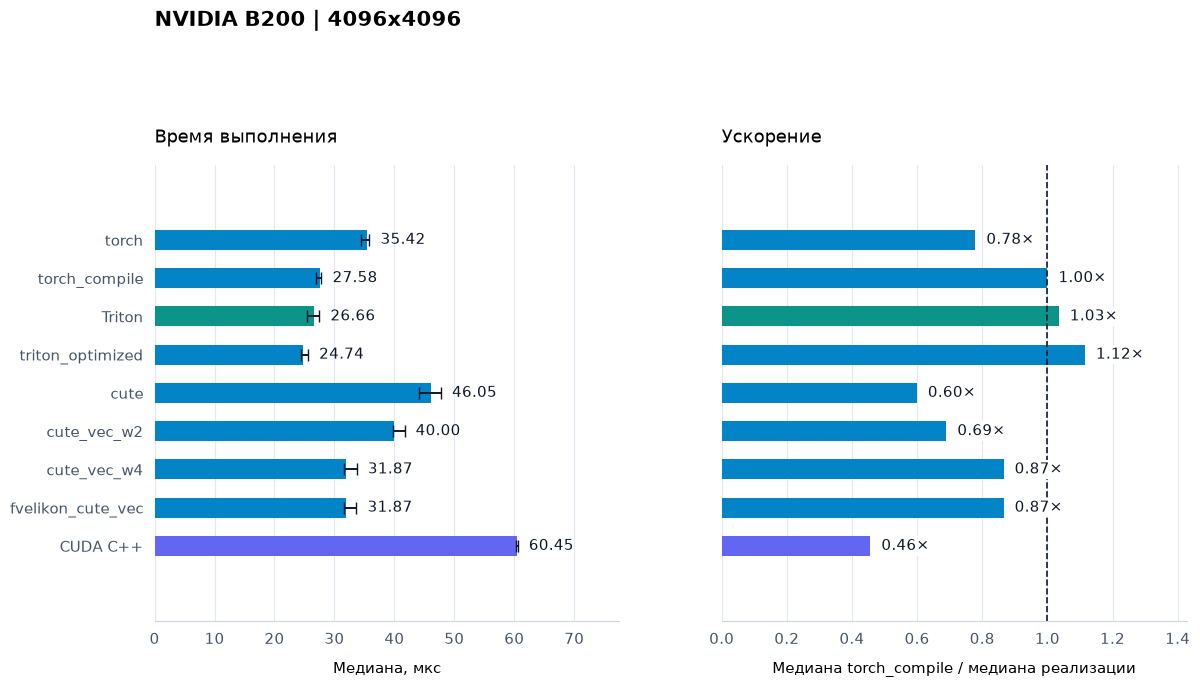

triton config: BLOCK_SIZE: 2048, num_warps: 8, num_ctas: 1, num_stages: 3, maxnreg: None
triton_optimized config: ROWS_PER_PROGRAM: 1, num_warps: 4, num_ctas: 1, num_stages: 3, maxnreg: None


cute config: {'threads_per_block': 128}


cute_vec_w2 config: {'WIDTH': 2, 'threads_per_block': 256}


cute_vec_w4 config: {'WIDTH': 4, 'threads_per_block': 256}


fvelikon_cute_vec config: {'threads_per_block': 256}


In [4]:
# Square, add, multiply by 1/rms, multiply by w.
inputs = make_inputs((M, N), (N,))
implementations = {
    name: fn for name, fn in IMPLEMENTATIONS.items() if N % VECTOR_WIDTHS.get(name, 1) == 0
}
results = run_benchmark(implementations, inputs, reference=rmsnorm, flops=4 * M * N)
plot_benchmark(results, baseline="torch_compile", title=f"{torch.cuda.get_device_name()} | {M}x{N}")
plt.show()
if AUTOTUNE:
    for name, kernel in zip(("triton", "triton_optimized"), TRITON_KERNELS):
        print(f"{name} config: {kernel.best_config}")
    for name in ("cute", *VECTOR_WIDTHS):
        if name in implementations:
            config = next(iter(implementations[name].asm().values()))["config"]
            print(f"{name} config: {config}")

In [5]:
EXPORT_ASM = False
if EXPORT_ASM:
    for name, fn in implementations.items():
        listing = fn.asm()
        dump_asm(listing, RMSNORM_DIR / "m4xig1" / "asm" / "bench" / name)
        print(name, list(listing))